# Lab 1

Name: Aljoscha Ziegler

Student id: 261355852

Lab section: Tuesday

In [1]:
import numpy as np # import built-in librairies (super useful)
import matplotlib.pyplot as plt
# make graphics show up in Jupyter notebook
%matplotlib inline 
import os
import pylab

def data_generator(mean, std, n_measurements = 500, n_samples = 20): # function name and arguments
    """
    Generates an array of measurements from a standard distribution.

    Parameters
    ----------
    mean : float
           Desired mean value of the measurements.
           
    std : float
          Desired standard deviation of the measurements.
          
    n_measurements : int, optional
                     Number of separate measurements. Default is 500 measurements.

    n_samples : int, optional
                Number of samples taken per measurement. Default is 20 samples. 
                per measurement.


    Returns
    -------
    data : ndarray, shape (n_measuremets, n_samples)
           Array representing the experimental data. Each measurement 
           (composed of many samples) is a row of this array:
                     -----------------------------------
            meas1    | sample0 | sample1 | sample2 | ...
            meas2    | sample0 | sample1 | sample2 | ...
            meas3    | sample0 | sample1 | sample2 | ...
             ...

    """
    # The following array has n_measurements rows, and n_samples columns
    return np.random.normal(loc = mean, scale = std, size = (n_measurements, n_samples))

In [2]:
os.getcwd()

'c:\\Users\\aljos\\.vscode\\uni_classes\\experimental_physics'

In [3]:
data = np.genfromtxt("lab1-data.csv", delimiter = ",") # load data from csv file
data.shape # check the shape of the data array


(20, 5)

It makes sense to use the transpose to easily take the mean of each column, which will now be grouped by positions at the same moment of time. 

In [4]:
time_50_cm = data[:,0] # first column of the data array
time_40_cm = data[:,1] # second column of the data array
time_30_cm = data[:,2] # third column of the data array
time_20_cm = data[:,3] # fourth column of the data array
time_10_cm = data[:,4] # fifth column of the data array

print(time_50_cm) # print the first column of the data array

[  nan 2.779 2.774 2.783 2.773 2.773 2.776 2.774 2.769 2.771 2.777 2.776
 2.78  2.783 2.782 2.781 2.777 2.778 2.776 2.774]


In [5]:
averages = [np.nanmean(time_50_cm), np.nanmean(time_40_cm), np.nanmean(time_30_cm), np.nanmean(time_20_cm), np.nanmean(time_10_cm)]
standard_deviations = [np.nanstd(time_50_cm), np.nanstd(time_40_cm), np.nanstd(time_30_cm), np.nanstd(time_20_cm), np.nanstd(time_10_cm)]

print(averages)
print(standard_deviations)


[np.float64(2.7766315789473683), np.float64(2.4244499999999998), np.float64(2.0425999999999997), np.float64(1.6072000000000002), np.float64(1.1019)]
[np.float64(0.003882626977159547), np.float64(0.030801745080433377), np.float64(0.04199571406703313), np.float64(0.0172499275360797), np.float64(0.021658485634965335)]


In [6]:
simdata = data_generator(mean = averages[2], std = standard_deviations[2], n_measurements = 500, n_samples = 20) # generate simulated data
simdata.shape # check the shape of the simulated data array

(500, 20)

# Question 1

The mean of the simulated data is: 2.042807603391523
The standard deviation of the simulated data is: 0.0416861987518715


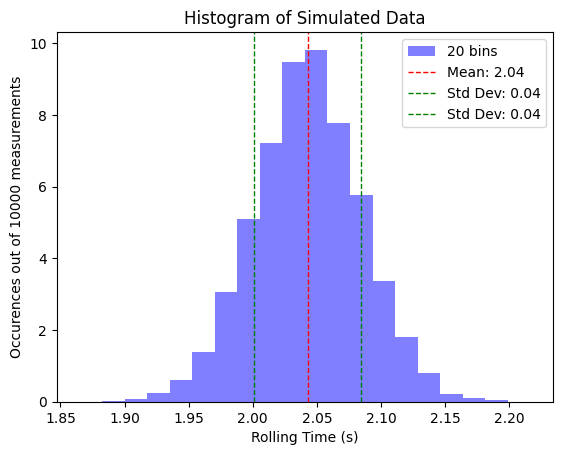

In [7]:

mean = np.average(simdata.flatten())
std = np.std(simdata.flatten(), ddof=1)
print(f'The mean of the simulated data is: {mean}')
print(f'The standard deviation of the simulated data is: {std}')



# plot with 20 bins 
plt.hist(simdata.flatten(), bins = 20, density = True, alpha = 0.5, color = 'b', label = '20 bins') # plot histogram of simulated data
plt.ylabel("Occurences out of 10000 measurements")
plt.xlabel("Rolling Time (s)")
plt.title('Histogram of Simulated Data')
# Add average and standard deviation to the plot
plt.axvline(mean, color='r', linestyle='dashed', linewidth=1, label=f'Mean: {mean:.2f}')
plt.axvline(mean + std, color='g', linestyle='dashed', linewidth=1, label=f'Std Dev: {std:.2f}')
plt.axvline(mean - std, color='g', linestyle='dashed', linewidth=1, label=f'Std Dev: {std:.2f}')
plt.legend()
plt.show()

The mean of the simulated data is: 2.042807603391523
The standard deviation of the simulated data is: 0.0416861987518715


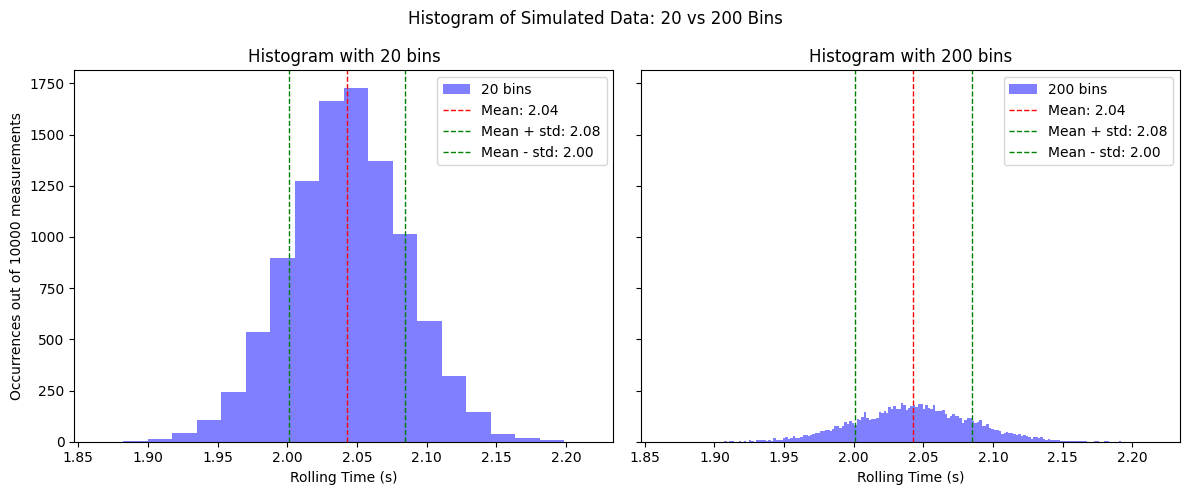

In [8]:
# Histogram of data with a different amount of bins

mean = np.average(simdata.flatten())
std = np.std(simdata.flatten(), ddof=1)
print(f'The mean of the simulated data is: {mean}')
print(f'The standard deviation of the simulated data is: {std}')

# Compare the same data using 20 and 200 bins
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for axis, number_of_bins in zip(axes, [20, 200]):
    axis.hist(
        simdata.flatten(),
        bins=number_of_bins,
        alpha=0.5,
        color='b',
        label=f'{number_of_bins} bins'
    )
    axis.axvline(mean, color='r', linestyle='dashed', linewidth=1,
                 label=f'Mean: {mean:.2f}')
    axis.axvline(mean + std, color='g', linestyle='dashed', linewidth=1,
                 label=f'Mean + std: {mean + std:.2f}')
    axis.axvline(mean - std, color='g', linestyle='dashed', linewidth=1,
                 label=f'Mean - std: {mean - std:.2f}')
    axis.set_xlabel("Rolling Time (s)")
    axis.set_title(f"Histogram with {number_of_bins} bins")
    axis.legend()

axes[0].set_ylabel("Occurrences out of 10000 measurements")
fig.suptitle("Histogram of Simulated Data: 20 vs 200 Bins")
fig.tight_layout()
plt.show()

As can be seen, the number of bins affects the "spikiness" of the graph. Furthermore, the shape is reduced since there are more bins. 

# Question 2

The mean of the means is: 2.042807603391523
The standard deviation of the means is: 0.00876476287852137


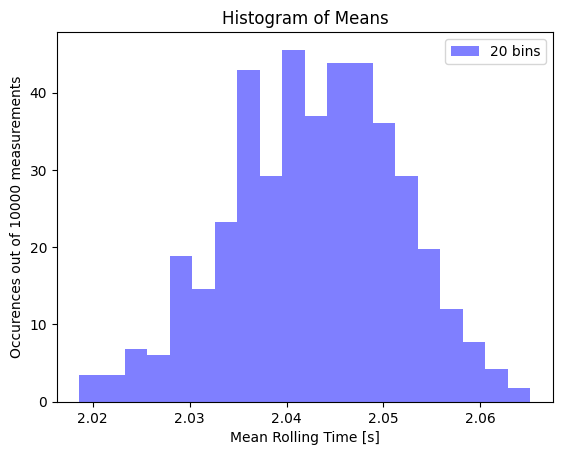

In [9]:

means = []
stds = []
# plot both histograms on the same plot to see the effect of binning on the histogram
for bin in simdata:
    means.append(np.average(bin))
    stds.append(np.std(bin, ddof=1))

mean_of_means = np.average(means)
std_of_means = np.std(means, ddof=1)

print(f'The mean of the means is: {mean_of_means}')
print(f'The standard deviation of the means is: {std_of_means}')

plt.hist(means, bins = 20, density = True, alpha = 0.5, color = 'b', label = '20 bins') # plot histogram of simulated data
plt.ylabel("Occurences out of 10000 measurements")
plt.xlabel("Mean Rolling Time [s]")
plt.title("Histogram of Means")
np.savetxt("Simulated_data_means.txt", means, delimiter = ",") # save simulated data to a text file
plt.legend()
plt.show()


The mean of the simulated data with 20 bins is: 2.0428332023509133
The mean of the simulated data with 200 bins is: 2.042807352642688
The standard deviation of the simulated data with 20 bins is: 0.041992770413793186
The standard deviation of the simulated data with 200 bins is: 0.04169045108475726


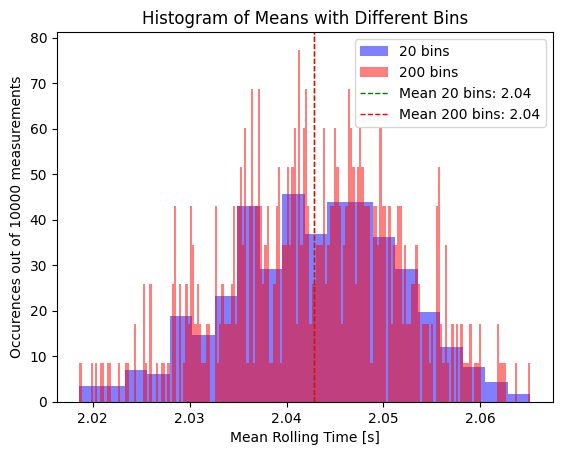

In [10]:
# Compare the effect of the number of bins on the histogram of the means
plt.hist(means, bins = 20, density = True, alpha = 0.5, color = 'b', label = '20 bins') # plot histogram of simulated data
plt.hist(means, bins = 200, density = True, alpha = 0.5, color = 'r', label = '200 bins') # plot histogram of simulated data
plt.ylabel("Occurences out of 10000 measurements")
plt.xlabel("Mean Rolling Time [s]")
plt.title("Histogram of Means with Different Bins")

# Calcualte the standard deviation and average of the means for different binning
# Compute the means for each bin of the histogram
counts, bin_edges = np.histogram(simdata.flatten(), bins=20)
bin_centers_20 = (bin_edges[:-1] + bin_edges[1:]) / 2


mean_20bins = bin_centers_20 @ counts / np.sum(counts) # Compute the weighted mean of the histogram
# Calculate the standard deviation of the histogram
std_20bins = np.sqrt(np.sum(counts * (bin_centers_20 - mean_20bins)**2) / np.sum(counts)) # STD for weighted distribution

counts, bin_edges = np.histogram(simdata.flatten(), bins=200)
bin_centers_200 = (bin_edges[:-1] + bin_edges[1:]) / 2

mean_200bins = bin_centers_200 @ counts / np.sum(counts)
std_200bins = np.sqrt(np.sum(counts * (bin_centers_200 - mean_200bins)**2) / np.sum(counts)) # STD for weighted distribution

print(f'The mean of the simulated data with 20 bins is: {mean_20bins}')
print(f'The mean of the simulated data with 200 bins is: {mean_200bins}')
print(f'The standard deviation of the simulated data with 20 bins is: {std_20bins}')
print(f'The standard deviation of the simulated data with 200 bins is: {std_200bins}')

# Plot the means for different binning
plt.axvline(mean_20bins, 0, 1, color='g', linestyle='dashed', linewidth=1, label=f'Mean 20 bins: {np.mean(mean_20bins):.2f}')
plt.axvline(mean_200bins, 0, 1, color='r', linestyle='dashed', linewidth=1, label=f'Mean 200 bins: {np.mean(mean_200bins):.2f}')
plt.legend()


The mean is basically identical (the green line is hidden by the red line), though the average with more bins is very slightly closer to the average of the distribution. Since the 200 bins is very spiky, the graph with 20 bins gives a better representation of the gaussian. 

# Question 3

The mean of the means is: 2.042807603391523
The standard deviation of the means is: 0.00876476287852137


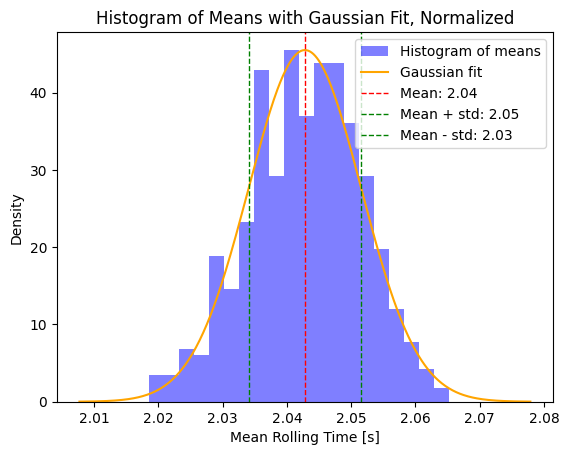

In [11]:
# Calculate the mean and standard deviation of each sample mean
means = []
stds = []
for measurement in simdata:
    means.append(np.average(measurement))
    stds.append(np.std(measurement, ddof=1))

mean_of_means = np.average(means)
std_of_means = np.std(means, ddof=1)

print(f'The mean of the means is: {mean_of_means}')
print(f'The standard deviation of the means is: {std_of_means}')

# Plot the histogram of means
plt.hist(
    means,
    bins=20,
    density=True,
    alpha=0.5,
    color='b',
    label='Histogram of means'
)

# Use +/- 4 standard deviations of the means for the Gaussian x-range
x = np.linspace(mean_of_means - 4 * std_of_means,
                mean_of_means + 4 * std_of_means,
                500)

# Define and plot the Gaussian for the distribution of means
def p(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(
        -(x - mu) ** 2 / (2 * sigma ** 2)
    )

y_values = p(x, mean_of_means, std_of_means)
plt.plot(x, y_values, color='orange', label='Gaussian fit')
plt.axvline(mean_of_means, color='r', linestyle='dashed', linewidth=1,
            label=f'Mean: {mean_of_means:.2f}')
plt.axvline(mean_of_means + std_of_means, color='g', linestyle='dashed', linewidth=1,
            label=f'Mean + std: {mean_of_means + std_of_means:.2f}')
plt.axvline(mean_of_means - std_of_means, color='g', linestyle='dashed', linewidth=1,
            label=f'Mean - std: {mean_of_means - std_of_means:.2f}')

plt.ylabel("Density")
plt.xlabel("Mean Rolling Time [s]")
plt.title("Histogram of Means with Gaussian Fit, Normalized")
np.savetxt("Simulated_data_means.txt", means, delimiter=",")
plt.legend()
plt.show()

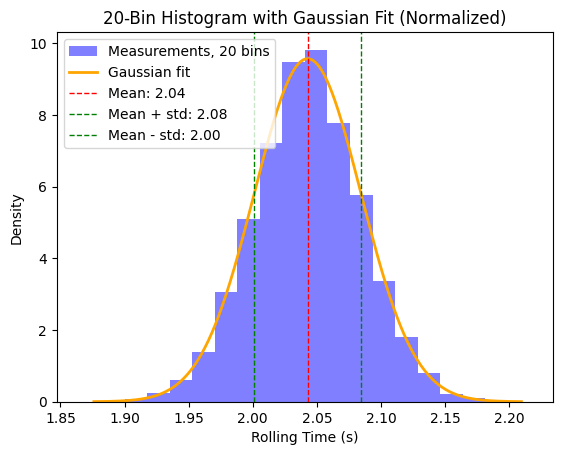

In [12]:
# Plot the normalized 20-bin histogram with its Gaussian fit
measurements = simdata.flatten()
mean_measurements = np.mean(measurements)
std_measurements = np.std(measurements, ddof=1)

x = np.linspace(
    mean_measurements - 4 * std_measurements,
    mean_measurements + 4 * std_measurements,
    500
)

def gaussian(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(
        -(x - mu) ** 2 / (2 * sigma ** 2)
    )

plt.hist(
    measurements,
    bins=20,
    density=True,
    alpha=0.5,
    color='b',
    label='Measurements, 20 bins'
)
plt.plot(
    x,
    gaussian(x, mean_measurements, std_measurements),
    color='orange',
    linewidth=2,
    label='Gaussian fit'
)
plt.axvline(
    mean_measurements,
    color='r',
    linestyle='dashed',
    linewidth=1,
    label=f'Mean: {mean_measurements:.2f}'
)
plt.axvline(
    mean_measurements + std_measurements,
    color='g',
    linestyle='dashed',
    linewidth=1,
    label=f'Mean + std: {mean_measurements + std_measurements:.2f}'
)
plt.axvline(
    mean_measurements - std_measurements,
    color='g',
    linestyle='dashed',
    linewidth=1,
    label=f'Mean - std: {mean_measurements - std_measurements:.2f}'
)

plt.xlabel("Rolling Time (s)")
plt.ylabel("Density")
plt.title("20-Bin Histogram with Gaussian Fit (Normalized)")
plt.legend()
plt.show()


# Question 4


The mean of the distribution of results is: 2.042807603391523

The mean of the distribution of individual measurements is: 2.043119237293389

The std of the distribution of results is (20 bins): 0.00961341206726736

The std of the distribution of individual measurements is: 0.04215100106353454

The mean of the distribution of results is (20 bins, weighted average with bin): 2.0430726116110316

The weighed std of the distribution of 20 bins is: 0.04238062624477265

As can be seen the standard distribution of results (binned)(0.00961341206726736) is significantly smaller than the standard deviation of individual measurements (0.04215100106353454). This is to be expected as we should have a difference of 1/sqrt(20) due to the number of bins. 

# Question 5

In [13]:
sem = std / np.sqrt(20) # calculate the standard error of the mean
print(f'The standard error of the mean is: {sem}')

The standard error of the mean is: 0.009321317413275156


The standard error of the mean for the distribution of measurements is the same as the standard deviation of the distribution of results. 

# Question 6

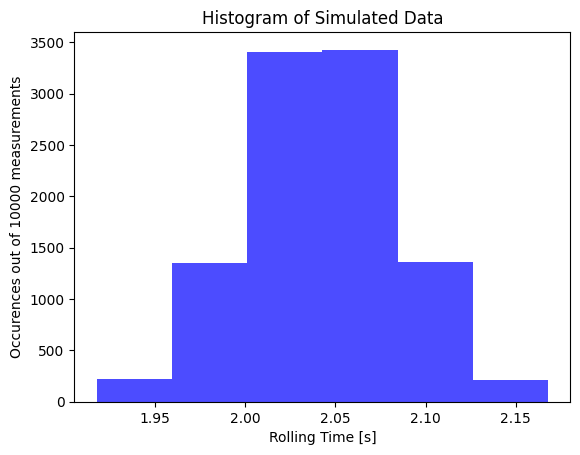

In [14]:
std_measurement_distribution = std
mean_measurement_distribution = mean

# Make 6 bins of size std_measurement_distribution 
bin_edges = np.linspace(mean_measurement_distribution - 3 * std_measurement_distribution, mean_measurement_distribution + 3 * std_measurement_distribution, 7)

# Find the counts for each bin edge
counts, _ = np.histogram(simdata.flatten(), bins=bin_edges)

# Plot the resulting histogram
plt.bar(bin_edges[:-1], counts, width=np.diff(bin_edges), align='edge', alpha=0.7, color='b')
plt.xlabel("Rolling Time [s]")
plt.ylabel("Occurences out of 10000 measurements")
plt.title("Histogram of Simulated Data")
# Save results
np.savetxt("Simulated_data_3bins_histogram.txt", np.column_stack((bin_edges[:-1], counts)), delimiter=",")
plt.show()

# Question 7

In [15]:
# Calculate the number of elements per group of bins
total_elements = 10000
one_sigma = (counts[3] + counts[2]) / total_elements * 100
two_sigma = (counts[4] + counts[1] + counts[3] + counts[2]) / total_elements * 100
three_sigma = (counts[5] + counts[0] + counts[4] + counts[1] + counts[3] + counts[2]) / total_elements * 100

print(f'Percentage of measurements within 1 sigma: {one_sigma:.2f}%')
print(f'Percentage of measurements within 2 sigma: {two_sigma:.2f}%')   
print(f'Percentage of measurements within 3 sigma: {three_sigma:.2f}%')

Percentage of measurements within 1 sigma: 68.29%
Percentage of measurements within 2 sigma: 95.34%
Percentage of measurements within 3 sigma: 99.66%


Yes! This is the expected distribution of values in a normal distribution. :)